# Import a Biacore Cycle/Fc text export

Import **`biacore_cycle_fc.tsv`**, inspect its metadata, and plot the measured
sensorgrams. This example uses a full-resolution selection committed with the repository;
it does not download data or fit a model.

**Data origin:** [RKI-ZBS Biacore T200 binning sensorgrams](https://github.com/RKI-ZBS/SPR_kinetics_binning/blob/ceaae964586dcbb00ac53bcae301bc097d92f3f4/Binning/Binning_Raw_Inspector_T200/input/2022-05-10_Kurven_Binning_huCapRaw.txt). Copyright (c) 2024 SternDan, MIT license.
This is a modified excerpt/conversion; the exact changes and pinned sources
are listed in [SOURCES.md](data/spr_exports/SOURCES.md).
The data and plotted sensorgrams retain their upstream license:
[full license notice](../test_files/spr_exports/SPR_kinetics_binning-LICENSE).

In [1]:
from pathlib import Path
import json
import sys

import pandas as pd

# Works from the repository root, notebooks/ or docs/notebooks/.
repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (p / "src" / "pykingenie").is_dir())
sys.path[:0] = [str(repo_root / "src"), str(repo_root / "notebooks")]

from pykingenie import KineticsAnalyzer
from pykingenie.utils.plotting import plot_association_dissociation, plot_traces_all
from notebook_helpers import show_plotly_static

data_folder = repo_root / "notebooks" / "data" / "spr_exports"
fit_metadata = json.loads((data_folder / "fit_metadata.json").read_text())

## File layout and representative selection

Tab-separated `Cycle=..._Fc=..._X` / `_Y` pairs with decimal commas, which the reader detects. This file retains the complete original cycles 1 and 2 at their recorded sampling resolution (1,105 and 1,104 points). No measurements are removed or downsampled.

This is an epitope-binning run, not a single association/dissociation experiment. The complete cycles contain large protocol transitions. No baseline or bulk correction is applied. Headers contain no analyte concentrations, so the concentration table remains `NaN`.

These exports do not establish injection-event timing. The boundaries below
remain **illustrative API partitions**, not verified experimental events.
Verify actual injection timing and concentrations before fitting. Boundaries
are seconds, and association is `[association_start, association_end)`.

The expected missing-concentration warning is displayed below.
`sample_id="unassigned"` is a grouping placeholder, not a recovered sample identity.

`pyKinetics.load` detects the file format (`spr_text`), reads the file with `SprTextExperiment.read_file` and adds the experiment to the analyzer; the keyword options go to that reader.

In [2]:
data_file = data_folder / "biacore_cycle_fc.tsv"

pyKinetics = KineticsAnalyzer()
experiment = pyKinetics.load(
    data_file,
    association_start=0,    # illustrative; replace with the actual timing
    association_end=300,    # illustrative; replace with the actual timing
    sample_id="unassigned",
)

/private/tmp/pykingenie-spr-input-parsers/src/pykingenie/utils/sensorgram_text.py:314: UserWarning: Some analyte concentrations are unavailable or have no unit. Provide concentrations or edit ligand_conc_df before fitting.
  warnings.warn(


## Imported curves and concentrations

Each measured curve becomes a sensor; its full exported label is kept as the
sensor name. `NaN` means the concentration is unknown, not zero. Supply verified
values with `concentrations=` and `concentration_unit=` before fitting.

In [3]:
experiment.ligand_conc_df

,Sensor,Analyte_location,Concentration_micromolar,SampleID,Replicate,Loading_location,Experiment
0,Cycle=1_Fc=4-3,1,NaN,unassigned,1,0,biacore_cycle_fc
1,Cycle=2_Fc=4-3,1,NaN,unassigned,1,0,biacore_cycle_fc


The three steps come from the boundaries passed to `load`, not from the signal.

In [4]:
experiment.df_steps

,#Step,Name,Type,Start,Column_location,Loading_location
0,1,Baseline,BASELINE,0.0,0,NaN
1,2,Association,ASSOC,0.0,1,0
2,3,Dissociation,DISASSOC,300.0,1,NaN


## Imported sensorgrams

All retained observations at their original times; no resampling, smoothing or baseline subtraction.

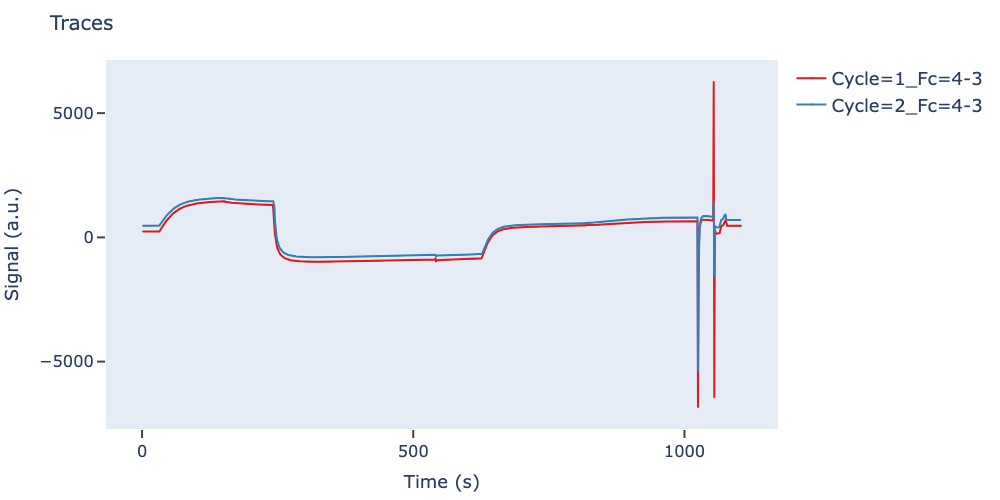

In [5]:
show_plotly_static(plot_traces_all(pyKinetics, pyKinetics.get_legends_table()),
                   width=1000, height=500, scale=1)

These teaching exports contain complete source sampling for the selected
curves, excluding only the explicitly documented missing pairs. Their original
offsets and independent time grids are preserved. The small files used for parser
regression tests remain separate in `test_files/spr_exports/`.

Selection details, missing-pair counts, provenance and licenses:
[SOURCES.md](data/spr_exports/SOURCES.md).